### 1. Импорты



In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mnist-dataset' dataset.
Path to dataset files: /kaggle/input/mnist-dataset


In [4]:
import numpy as np
import struct
from pathlib import Path
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

### 2. Базовая база

In [3]:
for dirpath, dirnames, filenames in os.walk(path):
    depth = dirpath.replace(path, "").count(os.sep)
    if depth <= 2:  # не углубляемся слишком сильно
        indent = "  " * depth
        print(f"{indent}{os.path.basename(dirpath)}/")
        if filenames:
            print(f"{indent}  └── файлов: {len(filenames)}, примеры: {filenames[:3]}")

mnist-dataset/
  └── файлов: 4, примеры: ['train-images.idx3-ubyte', 't10k-labels.idx1-ubyte', 't10k-images.idx3-ubyte']
  t10k-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['t10k-labels-idx1-ubyte']
  t10k-images-idx3-ubyte/
    └── файлов: 1, примеры: ['t10k-images-idx3-ubyte']
  train-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['train-labels-idx1-ubyte']
  train-images-idx3-ubyte/
    └── файлов: 1, примеры: ['train-images-idx3-ubyte']


In [6]:
ROOT = "/kaggle/input/mnist-dataset"

def read_idx_images(path):
    """Читает IDX-файл с изображениями → массив (N, rows*cols)."""
    with open(path, 'rb') as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        # Проверяем магическое число (2051 = 0x00000803)
        assert magic == 2051, f"Неверный magic number в {path}: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
        data = data.reshape(n, rows * cols)
    return data.astype(np.float32)

def read_idx_labels(path):
    """Читает IDX-файл с метками → массив (N,)."""
    with open(path, 'rb') as f:
        magic, n = struct.unpack(">II", f.read(8))
        # Проверяем магическое число (2049 = 0x00000801)
        assert magic == 2049, f"Неверный magic number в {path}: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.astype(int)

def load_mnist_idx(root_dir):
    """
    Загружает MNIST из IDX-файлов в стиле MedMNIST:
    возвращает (X_train, y_train, X_val, y_val, X_test, y_test).

    MNIST: 60000 train + 10000 test. Отделяем 10% от train под validation.
    """
    root = Path(root_dir)

    # Ищем файлы в корне (могут быть с дефисами или подчёркиваниями)
    def find_file(*candidates):
        for name in candidates:
            p = root / name
            if p.exists():
                return p
            # ищем рекурсивно на случай вложенных папок
            for sub in root.rglob(name):
                return sub
        raise FileNotFoundError(
            f"Не найден файл среди: {candidates} в {root_dir}"
        )

    train_images = find_file(
        "train-images.idx3-ubyte",
        "train-images-idx3-ubyte",
    )
    train_labels = find_file(
        "train-labels.idx1-ubyte",
        "train-labels-idx1-ubyte",
    )
    test_images = find_file(
        "t10k-images.idx3-ubyte",
        "t10k-images-idx3-ubyte",
    )
    test_labels = find_file(
        "t10k-labels.idx1-ubyte",
        "t10k-labels-idx1-ubyte",
    )

    print(f"Train images: {train_images}")
    print(f"Train labels: {train_labels}")
    print(f"Test  images: {test_images}")
    print(f"Test  labels: {test_labels}")

    # Загружаем
    X_train_full = read_idx_images(train_images)
    y_train_full = read_idx_labels(train_labels)
    X_test       = read_idx_images(test_images)
    y_test       = read_idx_labels(test_labels)

    # Отделяем validation (10% от train, стратифицированно)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full,
        test_size=0.1,
        random_state=42,
        stratify=y_train_full,
    )
    # Нормализация пикселей: [0, 255] → [0, 1]
    # В MedMNIST данные уже в [0, 1], приводим MNIST к тому же виду
    X_train = X_train / 255.0
    X_val   = X_val   / 255.0
    X_test  = X_test  / 255.0

    print(f"\nTrain:      X={X_train.shape}, y={y_train.shape}")
    print(f"Validation: X={X_val.shape},   y={y_val.shape}")
    print(f"Test:       X={X_test.shape},  y={y_test.shape}")

    return X_train, y_train, X_val, y_val, X_test, y_test

In [7]:
X_train, y_train, X_val, y_val, X_test, y_test = load_mnist_idx(ROOT)

Train images: /kaggle/input/mnist-dataset/train-images.idx3-ubyte
Train labels: /kaggle/input/mnist-dataset/train-labels.idx1-ubyte
Test  images: /kaggle/input/mnist-dataset/t10k-images.idx3-ubyte
Test  labels: /kaggle/input/mnist-dataset/t10k-labels.idx1-ubyte

Train:      X=(54000, 784), y=(54000,)
Validation: X=(6000, 784),   y=(6000,)
Test:       X=(10000, 784),  y=(10000,)


### 3. Анализ и примеры

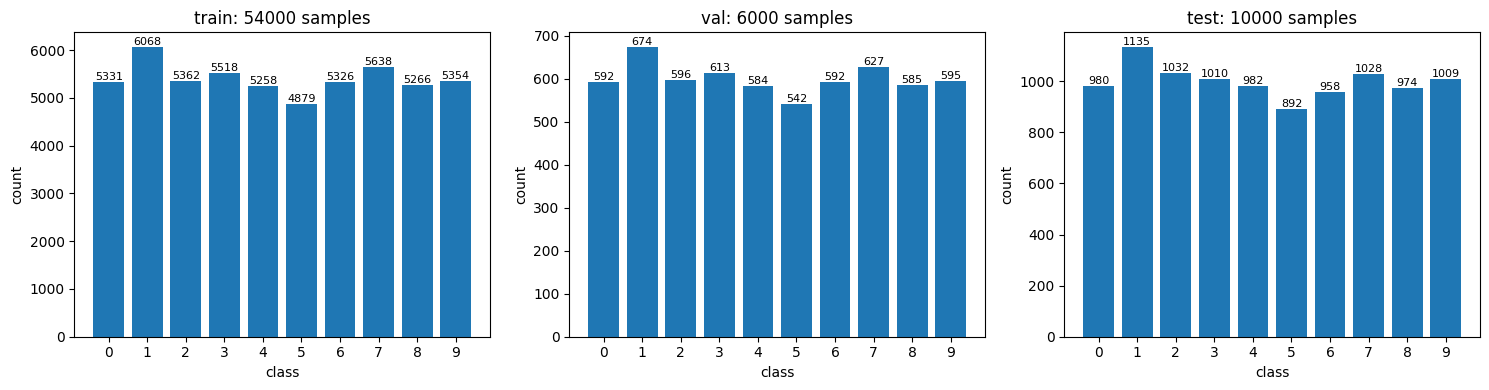

train {np.int64(0): 5331, np.int64(1): 6068, np.int64(2): 5362, np.int64(3): 5518, np.int64(4): 5258, np.int64(5): 4879, np.int64(6): 5326, np.int64(7): 5638, np.int64(8): 5266, np.int64(9): 5354} min/max = 4879 / 6068
val {np.int64(0): 592, np.int64(1): 674, np.int64(2): 596, np.int64(3): 613, np.int64(4): 584, np.int64(5): 542, np.int64(6): 592, np.int64(7): 627, np.int64(8): 585, np.int64(9): 595} min/max = 542 / 674
test {np.int64(0): 980, np.int64(1): 1135, np.int64(2): 1032, np.int64(3): 1010, np.int64(4): 982, np.int64(5): 892, np.int64(6): 958, np.int64(7): 1028, np.int64(8): 974, np.int64(9): 1009} min/max = 892 / 1135


In [9]:
import matplotlib.pyplot as plt
from collections import Counter

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, y) in zip(axes, [
        ("train", y_train), ("val", y_val), ("test", y_test)]):
    cnt = Counter(y)
    classes = sorted(cnt)
    ax.bar(classes, [cnt[c] for c in classes])
    ax.set_title(f"{name}: {len(y)} samples")
    ax.set_xlabel("class"); ax.set_ylabel("count")
    ax.set_xticks(classes)
    for c in classes:
        ax.text(c, cnt[c], str(cnt[c]), ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.show()

for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    cnt = Counter(y)
    print(name, {c: cnt[c] for c in sorted(cnt)},
          "min/max =", min(cnt.values()), "/", max(cnt.values()))

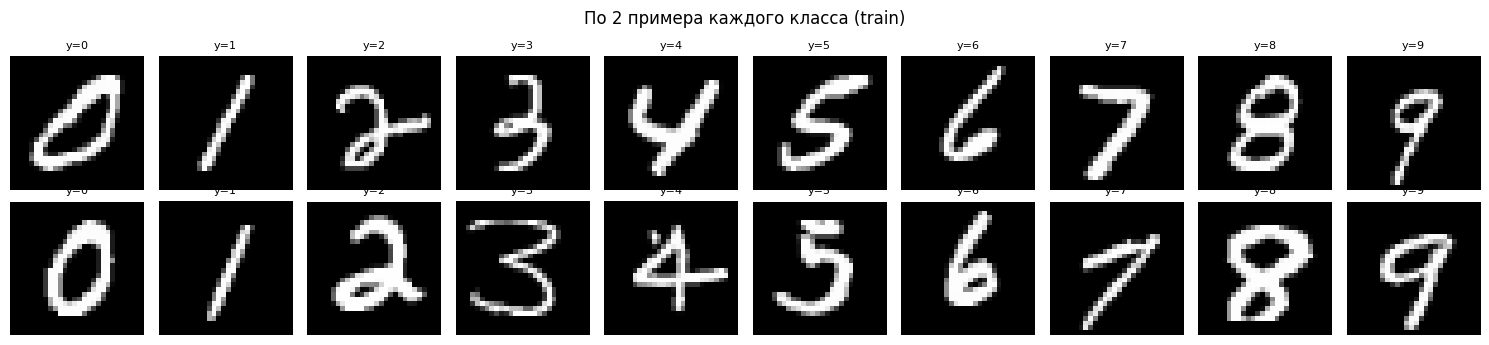

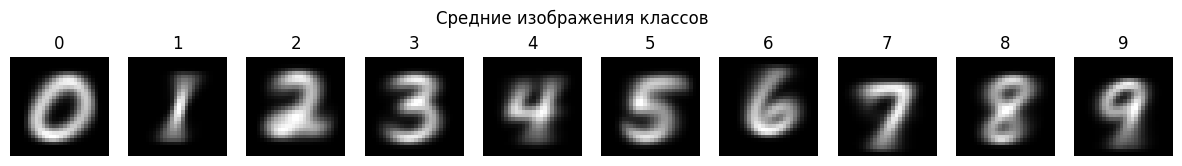

In [13]:
fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))
for cls in range(10):
    idx = np.where(y_train == cls)[0][:2]
    for row, i in enumerate(idx):
        ax = axes[row, cls]
        ax.imshow(X_train[i].reshape(28, 28), cmap='gray')
        ax.set_title(f"y={y_train[i]}", fontsize=8)
        ax.axis('off')
plt.suptitle("По 2 примера каждого класса (train)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for cls in range(10):
    axes[cls].imshow(X_train[y_train == cls].mean(0).reshape(28, 28), cmap='gray')
    axes[cls].set_title(str(cls)); axes[cls].axis('off')
plt.suptitle("Средние изображения классов")
plt.show()

### 4. Обучение пупупу

In [14]:
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

def evaluate(model, X_tr, y_tr, X_te, y_te, name):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    fit_time = time.time() - t0
    t0 = time.time()
    pred = model.predict(X_te)
    pred_time = time.time() - t0
    acc = accuracy_score(y_te, pred)
    f1  = f1_score(y_te, pred, average='macro')
    print(f"{name:40s} acc={acc:.4f}  macroF1={f1:.4f}  "
          f"fit={fit_time:6.1f}s  pred={pred_time:5.1f}s")
    return {"name": name, "acc": acc, "f1": f1,
            "fit_time": fit_time, "pred_time": pred_time}, pred

results = []

#без ограничения глубины
dt_full = DecisionTreeClassifier(random_state=42)
res, pred_dt = evaluate(dt_full, X_train, y_train, X_test, y_test,
                        "DecisionTree (no limit)")
results.append(res)
print("  depth =", dt_full.get_depth(), " leaves =", dt_full.get_n_leaves())

#с ограничением глубины
dt_lim = DecisionTreeClassifier(max_depth=10, random_state=42)
res, _ = evaluate(dt_lim, X_train, y_train, X_test, y_test,
                  "DecisionTree (max_depth=10)")
results.append(res)

#случайный лес
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
res, pred_rf = evaluate(rf, X_train, y_train, X_test, y_test,
                        "RandomForest (100 trees)")
results.append(res)

#бустинг
hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1,
                                     random_state=42)
res, pred_hgb = evaluate(hgb, X_train, y_train, X_test, y_test,
                         "HistGradientBoosting (200 iters)")
results.append(res)

DecisionTree (no limit)                  acc=0.8680  macroF1=0.8663  fit=  22.7s  pred=  0.0s
  depth = 48  leaves = 3633
DecisionTree (max_depth=10)              acc=0.8625  macroF1=0.8609  fit=   8.7s  pred=  0.0s
RandomForest (100 trees)                 acc=0.9696  macroF1=0.9693  fit=  26.2s  pred=  0.3s


KeyboardInterrupt: 